# Tensorflow with GPU

This notebook provides an introduction to computing on a [GPU](https://cloud.google.com/gpu) in Colab. In this notebook you will connect to a GPU, and then run some basic TensorFlow operations on both the CPU and a GPU, observing the speedup provided by using the GPU.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Go to this URL in a browser: https://accounts.google.com/o/oauth2/auth?client_id=947318989803-6bn6qk8qdgf4n4g3pfee6491hc0brc4i.apps.googleusercontent.com&redirect_uri=urn%3aietf%3awg%3aoauth%3a2.0%3aoob&response_type=code&scope=email%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdocs.test%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdrive%20https%3a%2f%2fwww.googleapis.com%2fauth%2fdrive.photos.readonly%20https%3a%2f%2fwww.googleapis.com%2fauth%2fpeopleapi.readonly

Enter your authorization code:
··········
Mounted at /content/drive


## Enabling and testing the GPU

First, you'll need to enable GPUs for the notebook:

- Navigate to Edit→Notebook Settings
- select GPU from the Hardware Accelerator drop-down

Next, we'll confirm that we can connect to the GPU with tensorflow:

In [ ]:
%tensorflow_version 2.x
import tensorflow as tf
device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
  raise SystemError('GPU device not found')
print('Found GPU at: {}'.format(device_name))

Found GPU at: /device:GPU:0


## Observe TensorFlow speedup on GPU relative to CPU

This example constructs a typical convolutional neural network layer over a
random image and manually places the resulting ops on either the CPU or the GPU
to compare execution speed.

In [ ]:
%tensorflow_version 2.x
import tensorflow as tf
import timeit

device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
  print(
      '\n\nThis error most likely means that this notebook is not '
      'configured to use a GPU.  Change this in Notebook Settings via the '
      'command palette (cmd/ctrl-shift-P) or the Edit menu.\n\n')
  raise SystemError('GPU device not found')

def cpu():
  with tf.device('/cpu:0'):
    random_image_cpu = tf.random.normal((100, 100, 100, 3))
    net_cpu = tf.keras.layers.Conv2D(32, 7)(random_image_cpu)
    return tf.math.reduce_sum(net_cpu)

def gpu():
  with tf.device('/device:GPU:0'):
    random_image_gpu = tf.random.normal((100, 100, 100, 3))
    net_gpu = tf.keras.layers.Conv2D(32, 7)(random_image_gpu)
    return tf.math.reduce_sum(net_gpu)
  
# We run each op once to warm up; see: https://stackoverflow.com/a/45067900
cpu()
gpu()

# Run the op several times.
print('Time (s) to convolve 32x7x7x3 filter over random 100x100x100x3 images '
      '(batch x height x width x channel). Sum of ten runs.')
print('CPU (s):')
cpu_time = timeit.timeit('cpu()', number=10, setup="from __main__ import cpu")
print(cpu_time)
print('GPU (s):')
gpu_time = timeit.timeit('gpu()', number=10, setup="from __main__ import gpu")
print(gpu_time)
print('GPU speedup over CPU: {}x'.format(int(cpu_time/gpu_time)))

Time (s) to convolve 32x7x7x3 filter over random 100x100x100x3 images (batch x height x width x channel). Sum of ten runs.
CPU (s):
3.809892057999946
GPU (s):
0.1822921299999507
GPU speedup over CPU: 20x


# Ethnicity training

In [ ]:
import pandas as pd
import numpy as np
import time
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
%matplotlib inline 

In [ ]:
train_df = pd.read_csv("/content/drive/My Drive/School Stuff/Ethnicity/fairface_label_train.csv")
test_df = pd.read_csv("/content/drive/My Drive/School Stuff/Ethnicity/fairface_label_val.csv")

In [ ]:
100*train_df.groupby(['race']).count()[['file']]/train_df.groupby(['race']).count()[['file']].sum()

,file
race,
Chinese,25.0
Indian,25.0
Malay,25.0
Others,25.0


In [ ]:
train_df.head()

,file,age,gender,race,service_test
0,train/1.jpg,50-59,Male,Malay,True
1,train/2.jpg,30-39,Female,Indian,False
2,train/3.jpg,3-Sep,Female,Others,False
3,train/4.jpg,20-29,Female,Indian,True
4,train/5.jpg,20-29,Female,Indian,True


In [ ]:
train_df.count

<bound method DataFrame.count of                file    age  gender     race  service_test
0       train/1.jpg  50-59    Male    Malay          True
1       train/2.jpg  30-39  Female   Indian         False
2       train/3.jpg  3-Sep  Female   Others         False
3       train/4.jpg  20-29  Female   Indian          True
4       train/5.jpg  20-29  Female   Indian          True
..              ...    ...     ...      ...           ...
795  train/1712.jpg  30-39    Male  Chinese         False
796  train/1724.jpg  20-29    Male  Chinese          True
797  train/1726.jpg  20-29    Male  Chinese         False
798  train/1749.jpg  20-29    Male  Chinese          True
799  train/1751.jpg  30-39    Male  Chinese         False

[800 rows x 5 columns]>

In [ ]:
from keras.preprocessing import image
target_size = (224, 224)
def getImagePixels(file):
    prepend = "/content/drive/My Drive/School Stuff/Ethnicity/Dataset/"
    img = image.load_img(prepend + file, grayscale=False, target_size=target_size)
    x = image.img_to_array(img).reshape(1, -1)[0]
    return x

In [ ]:
from tqdm.notebook import tqdm
tqdm.pandas()
import ipywidgets as widgets 

In [ ]:
train_df['pixels'] = train_df['file'].progress_apply(getImagePixels)

In [ ]:
test_df['pixels'] = test_df['file'].progress_apply(getImagePixels)

In [ ]:
train_df.head()

,file,age,gender,race,service_test,pixels
0,train/1.jpg,50-59,Male,Malay,True,"[8.0, 8.0, 10.0, 9.0, 9.0, 11.0, 10.0, 8.0, 11..."
1,train/2.jpg,30-39,Female,Indian,False,"[129.0, 127.0, 104.0, 127.0, 125.0, 102.0, 123..."
2,train/3.jpg,3-Sep,Female,Others,False,"[216.0, 171.0, 174.0, 212.0, 167.0, 170.0, 206..."
3,train/4.jpg,20-29,Female,Indian,True,"[42.0, 47.0, 50.0, 42.0, 47.0, 50.0, 41.0, 46...."
4,train/5.jpg,20-29,Female,Indian,True,"[44.0, 39.0, 35.0, 44.0, 39.0, 35.0, 43.0, 40...."


## input features
Pixels are stored as a list. We need to reshape each line to (224, 224, 3). Besides, inputs should be normalized in neural networks because of activation functions. This is going to be input feature we will pass to the network as input.



In [ ]:
tic = time.time()
train_features = []
 
for i in range(0, train_df.shape[0]):
    train_features.append(train_df['pixels'].values[i])

train_features = np.array(train_features)
train_features = train_features.reshape(train_features.shape[0], 224, 224, 3)

train_features /= 255

toc = time.time()

print("train_features converted to numpy in ",toc-tic,"seconds")

train_features converted to numpy in  0.24648022651672363 seconds


In [ ]:
tic = time.time()

test_features = []

for i in range(0, test_df.shape[0]):
    test_features.append(test_df['pixels'].values[i])

test_features = np.array(test_features)
test_features = test_features.reshape(test_features.shape[0], 224, 224, 3)
 
test_features = test_features / 255

toc = time.time()

print("test_features converted to numpy in ",toc-tic,"seconds")

test_features converted to numpy in  0.3835439682006836 seconds


In [ ]:
print(train_features.shape)

(800, 224, 224, 3)


In [ ]:
train_label = train_df[['race']] 
test_label = test_df[['race']]

races = train_df['race'].unique()
 
for j in range(len(races)): #label encoding
    current_race = races[j]
    print("replacing ",current_race," to ", j+1)
    train_label['race'] = train_label['race'].replace(current_race, str(j+1))
    test_label['race'] = test_label['race'].replace(current_race, str(j+1))
 
train_label = train_label.astype({'race': 'int32'})
test_label = test_label.astype({'race': 'int32'})
 
train_target = pd.get_dummies(train_label['race'], prefix='race')
test_target = pd.get_dummies(test_label['race'], prefix='race')

replacing  Malay  to  1
replacing  Indian  to  2
replacing  Others  to  3
replacing  Chinese  to  4


/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  if __name__ == '__main__':
/usr/local/lib/python3.6/dist-packages/ipykernel_launcher.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  # Remove the CWD from sys.path while we load stuff.


#Train and Validation Split

In [ ]:
tic = time.time()
train_x, val_x, train_y, val_y = train_test_split(
    train_features, train_target.values
    , test_size=0.12, random_state=17
)
toc = time.time()
print("train-test split in ",toc-tic,"seconds")

train-test split in  0.1305243968963623 seconds


#Base Model
We use VGG-Face for transfer training

In [ ]:
from keras.models import Model, Sequential
from keras.layers import Input, Convolution2D, ZeroPadding2D, MaxPooling2D, Flatten, Dense, Dropout, Activation
from keras.optimizers import Adam

model = Sequential()
model.add(ZeroPadding2D((1,1),input_shape=(224,224, 3)))
model.add(Convolution2D(64, (3, 3), activation='relu'))
model.add(ZeroPadding2D((1,1)))
model.add(Convolution2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2,2), strides=(2,2)))
 
model.add(ZeroPadding2D((1,1)))
model.add(Convolution2D(128, (3, 3), activation='relu'))
model.add(ZeroPadding2D((1,1)))
model.add(Convolution2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D((2,2), strides=(2,2)))
 
model.add(ZeroPadding2D((1,1)))
model.add(Convolution2D(256, (3, 3), activation='relu'))
model.add(ZeroPadding2D((1,1)))
model.add(Convolution2D(256, (3, 3), activation='relu'))
model.add(ZeroPadding2D((1,1)))
model.add(Convolution2D(256, (3, 3), activation='relu'))
model.add(MaxPooling2D((2,2), strides=(2,2)))
 
model.add(ZeroPadding2D((1,1)))
model.add(Convolution2D(512, (3, 3), activation='relu'))
model.add(ZeroPadding2D((1,1)))
model.add(Convolution2D(512, (3, 3), activation='relu'))
model.add(ZeroPadding2D((1,1)))
model.add(Convolution2D(512, (3, 3), activation='relu'))
model.add(MaxPooling2D((2,2), strides=(2,2)))
 
model.add(ZeroPadding2D((1,1)))
model.add(Convolution2D(512, (3, 3), activation='relu'))
model.add(ZeroPadding2D((1,1)))
model.add(Convolution2D(512, (3, 3), activation='relu'))
model.add(ZeroPadding2D((1,1)))
model.add(Convolution2D(512, (3, 3), activation='relu'))
model.add(MaxPooling2D((2,2), strides=(2,2)))
 
model.add(Convolution2D(4096, (7, 7), activation='relu'))
model.add(Dropout(0.5))
model.add(Convolution2D(4096, (1, 1), activation='relu'))
model.add(Dropout(0.5))
model.add(Convolution2D(2622, (1, 1)))
model.add(Flatten())
model.add(Activation('softmax'))
 
#related blog post: https://sefiks.com/2018/08/06/deep-face-recognition-with-keras/
model.load_weights('/content/drive/My Drive/School Stuff/Ethnicity/vgg_face_weights.h5')

#Transfer Learning
Its early layers can detect some facial patterns already. We do not have to train it from scratch. Because we do not have millions of train set instances. We can lock its early layers and expect the late layers to learn.

In [ ]:
#freeze all layers of VGG-Face except last 7 one
for layer in model.layers[:-7]:
    layer.trainable = False

In this way, its all layers except the last 7 one are locked and its weights will not be updated. We expect its last 7 layers to learn something.

The original VGG-Face network has 2622 outputs but here we need just 6 outputs related to races. We will customize the VGG-Face here and it is going to be VGG-Race now.

In [ ]:
num_of_classes = len(races)
base_model_output = Sequential()
base_model_output = Convolution2D(num_of_classes, (1, 1), name='predictions')(model.layers[-4].output)
base_model_output = Flatten()(base_model_output)
base_model_output = Activation('softmax')(base_model_output)
 
race_model = Model(inputs=model.input, outputs=base_model_output)

## Training
Instead of feeding all train data, I prefer to feed it as batches. I got the best result for 16.384 (2^14) batch size. I feed randomly selected 16K instances in every epoch. If validation loss would not decrease for 50 rounds, then training should be terminated to avoid overfitting.

In [ ]:
aug = ImageDataGenerator()

In [ ]:
from keras.callbacks import ModelCheckpoint

epochs = 250
race_model.compile(loss='categorical_crossentropy', 
                   optimizer=Adam(), metrics=['accuracy'])
 
checkpointer = ModelCheckpoint(filepath='/content/drive/My Drive/race_model_single_batch.hdf5', 
                               monitor = "val_loss", verbose=1, save_best_only=True, mode = 'auto')
 
batch_size = pow(2, 7); patience = 50
last_improvement = 0; best_iteration = 0
loss = 1000000 #initialize as a large value
val_scores=[]
train_scores=[]

for i in range(0, epochs):
  print("Epoch ", i, ". ", end='')
  ix_train = np.random.choice(train_x.shape[0], size=batch_size)
  
  aug = ImageDataGenerator(
      rotation_range=20,
		  zoom_range=0.15,
	    width_shift_range=0.2,
		  height_shift_range=0.2,
		  shear_range=0.15,
		  horizontal_flip=True,
      vertical_flip=True,
		  fill_mode="nearest"
      )
  
  score = race_model.fit(
      train_x[ix_train], train_y[ix_train]
      , epochs=1
      , validation_data=(val_x, val_y)
      , callbacks=[checkpointer]
      )
  
  val_loss = score.history['val_loss'][0]; train_loss = score.history['loss'][0]
  val_scores.append(val_loss); train_scores.append(train_loss)
  
  if val_loss < loss:
    loss = val_loss * 1
    last_improvement = 0
    best_iteration = i * 1
  else:
    last_improvement = last_improvement + 1
    print("try to decrease val loss for ",patience - last_improvement," epochs more")
  
  if last_improvement == patience:
    print("there is no loss decrease in validation for ",patience," epochs. early stopped")
    break

4/4 [==============================] - ETA: 0s - loss: 1.3257 - accuracy: 0.3516WARNING:tensorflow:Callbacks method `on_test_batch_end` is slow compared to the batch time (batch time: 0.0102s vs `on_test_batch_end` time: 0.3459s). Check your callbacks.

Epoch 00001: val_loss improved from inf to 1.42446, saving model to /content/drive/My Drive/race_model_single_batch.hdf5
4/4 [==============================] - ETA: 0s - loss: 1.2535 - accuracy: 0.4922WARNING:tensorflow:Callbacks method `on_test_batch_end` is slow compared to the batch time (batch time: 0.0103s vs `on_test_batch_end` time: 0.3462s). Check your callbacks.

Epoch 00001: val_loss improved from 1.42446 to 1.34227, saving model to /content/drive/My Drive/race_model_single_batch.hdf5
4/4 [==============================] - ETA: 0s - loss: 1.1444 - accuracy: 0.4609WARNING:tensorflow:Callbacks method `on_test_batch_end` is slow compared to the batch time (batch time: 0.0100s vs `on_test_batch_end` time: 0.3529s). Check your call

## Loss
train loss decreased while validation loss increased when epoch > 7 (in this case, indicating overfitting)

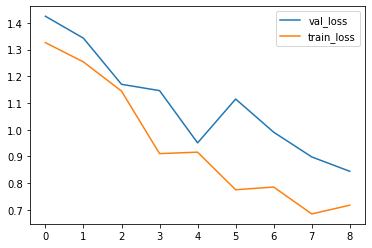

In [ ]:
plt.plot(val_scores[0:best_iteration+1], label='val_loss')
plt.plot(train_scores[0:best_iteration+1], label='train_loss')
plt.legend(loc='upper right')
plt.show()

## Evaluation
We train the network with train data set and use validation set to apply early stop. Epoch is the best iteration for validation set actually. However, network could memorize the validation set and it could still be overfitted. That’s why, we haven’t feed test set to the network yet. We expect that test and validation loss should be close if the model is robust.

In [ ]:
# test_label = test_df[['race']]
# races = train_df['race'].unique()
# for j in range(len(races)): #label encoding
#     current_race = races[j]
#     print("replacing ",current_race," to ", j+1)
#     test_label['race'] = test_label['race'].replace(current_race, str(j+1))
 
# test_label = test_label.astype({'race': 'int32'})
 
# test_target = pd.get_dummies(test_label['race'], prefix='race')

In [ ]:
from keras.models import load_model
race_model = load_model("/content/drive/My Drive/race_model_single_batch.hdf5")
race_model.save_weights('/content/drive/My Drive/race_model_single_batch.h5')

test_perf = race_model.evaluate(test_features, test_target.values, verbose=1)
print(test_perf)
 
validation_perf = race_model.evaluate(val_x, val_y, verbose=1)
print(validation_perf)
 
abs(validation_perf[0] - test_perf[0])

25/25 [==============================] - 9s 365ms/step - loss: 0.9462 - accuracy: 0.5738
[0.946244478225708, 0.5737500190734863]
3/3 [==============================] - 1s 349ms/step - loss: 0.8443 - accuracy: 0.6667
[0.8443074226379395, 0.6666666865348816]


0.10193705558776855

## Prediction

0
Actual:  Malay
Predicted:  Chinese


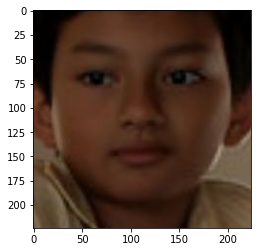

1
Actual:  Malay
Predicted:  Malay


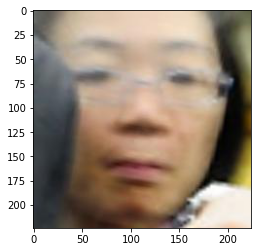

3
Actual:  Others
Predicted:  Chinese


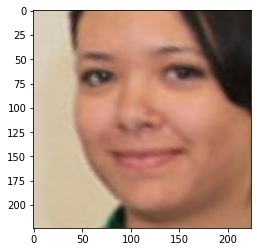

4
Actual:  Chinese
Predicted:  Indian


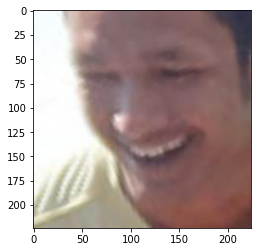

5
Actual:  Others
Predicted:  Indian


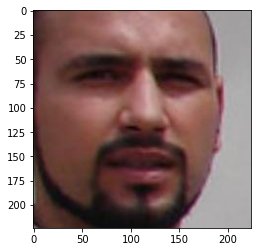

6
Actual:  Others
Predicted:  Indian


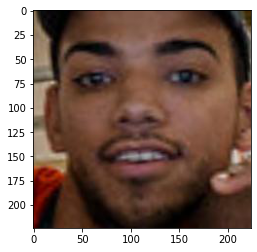

8
Actual:  Chinese
Predicted:  Chinese


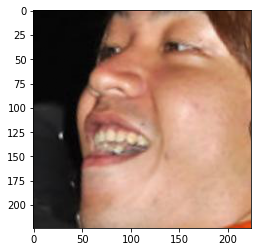

9
Actual:  Chinese
Predicted:  Chinese


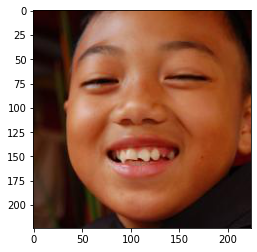

10
Actual:  Malay
Predicted:  Chinese


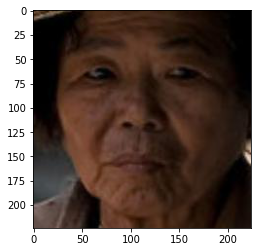

11
Actual:  Malay
Predicted:  Others


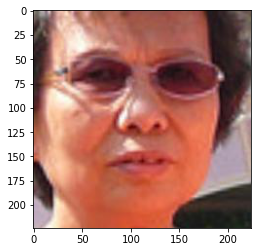

13
Actual:  Indian
Predicted:  Indian


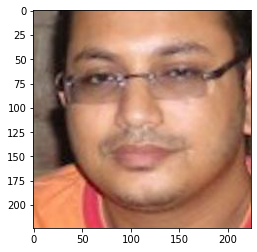

14
Actual:  Others
Predicted:  Indian


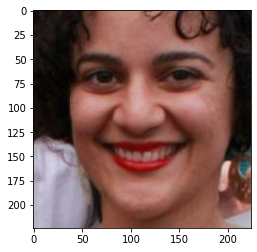

16
Actual:  Malay
Predicted:  Chinese


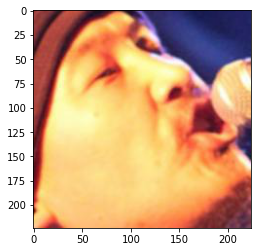

28
Actual:  Malay
Predicted:  Malay


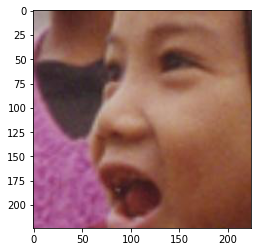

31
Actual:  Indian
Predicted:  Indian


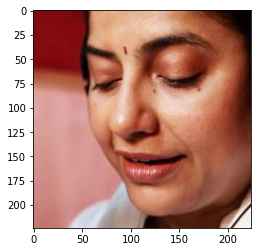

32
Actual:  Chinese
Predicted:  Chinese


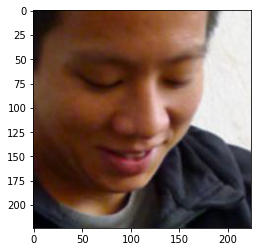

40
Actual:  Malay
Predicted:  Malay


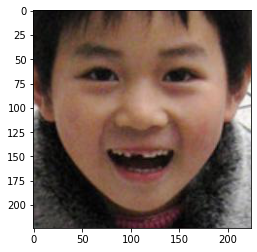

41
Actual:  Indian
Predicted:  Indian


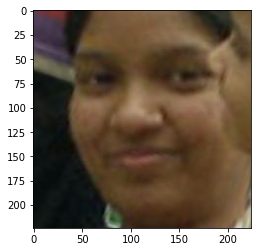

42
Actual:  Others
Predicted:  Others


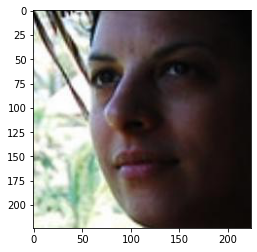

54
Actual:  Others
Predicted:  Indian


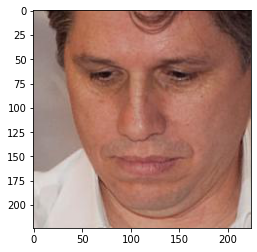

55
Actual:  Others
Predicted:  Indian


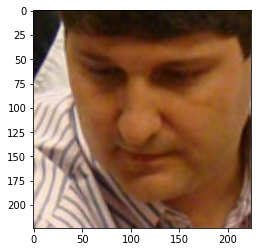

59
Actual:  Chinese
Predicted:  Chinese


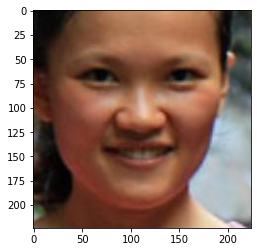

91
Actual:  Others
Predicted:  Others


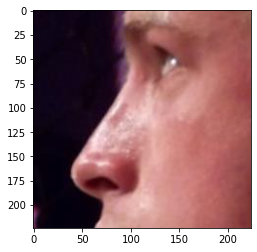

93
Actual:  Others
Predicted:  Others


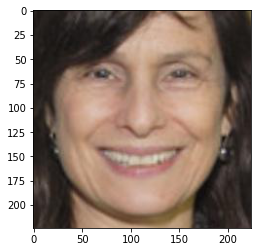

95
Actual:  Others
Predicted:  Others


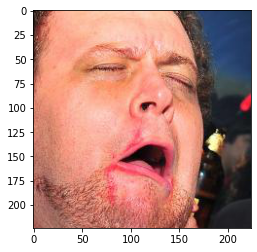

105
Actual:  Others
Predicted:  Indian


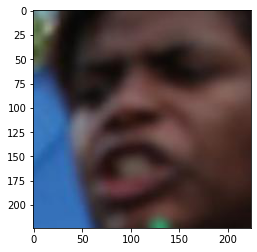

138
Actual:  Others
Predicted:  Indian


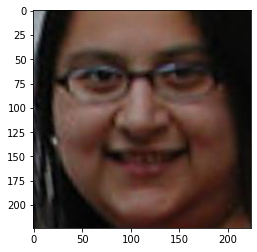

162
Actual:  Malay
Predicted:  Malay


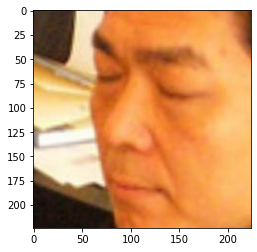

180
Actual:  Others
Predicted:  Indian


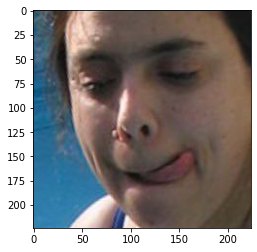

183
Actual:  Others
Predicted:  Others


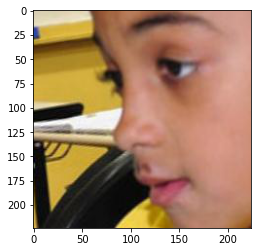

212
Actual:  Others
Predicted:  Chinese


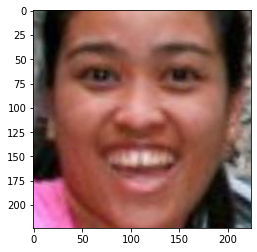

221
Actual:  Others
Predicted:  Indian


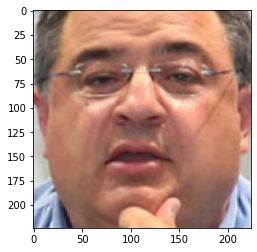

222
Actual:  Others
Predicted:  Indian


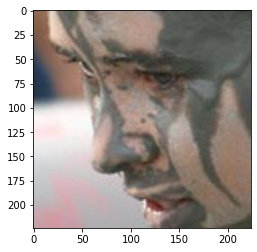

255
Actual:  Chinese
Predicted:  Chinese


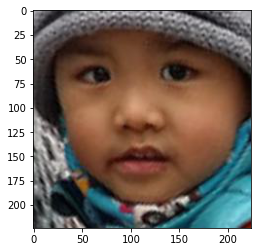

256
Actual:  Others
Predicted:  Others


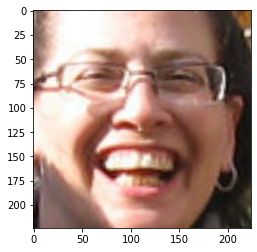

In [ ]:
prediction_classes=[]
actual_classes=[]
predictions = race_model.predict(test_features)
for i in range(0, predictions.shape[0]):
    prediction = np.argmax(predictions[i])
    prediction_classes.append(races[prediction])
 
    actual = np.argmax(test_target.values[i])
    actual_classes.append(races[actual])
 
    if i in [
             0, 1, 8, 10, 11, 16, 41, 54, 95, 138, 162 #malay
             , 5, 9, 28, 180, 183, 255, 256 #Chinese
             , 13, 14, 31, 32, 40, 42, 91, 93 #indian
             , 3, 4, 6, 55, 59, 105, 212, 221, 222 #others
    ]:
        print(i)
        print("Actual: ",races[actual])
        print("Predicted: ",races[prediction])
        img = (test_df.iloc[i]['pixels'].reshape([224, 224, 3])) / 255
        plt.imshow(img); plt.show()

## Confusion matrix
Accuracy does not mean anything for classification problems. We need precision and recall values. Confusion matrix is the best way to monitor the success of your model.

/usr/local/lib/python3.6/dist-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


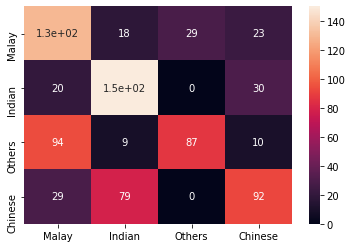

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sn
 
cm = confusion_matrix(actual_classes, prediction_classes)
df_cm = pd.DataFrame(cm, index=races, columns=races)
sn.heatmap(df_cm, annot=True,annot_kws={"size": 10})
